# Task 1 — 几何对仿真 HRTF 的预测，是否好于对实测 HRTF？

**2026-10-11 建。** 一页 workplan 的 Task 1：用同样的几何输入、同样的回归器、同样的受试者和折，分别预测
**仿真**和**实测** HRTF，比较两者。仿真里没有测量带来的变化（麦克风位置、重复佩戴、采集时段），
所以如果仿真明显更好预测，主要限制就是扫描与测量之间的失配；如果两者都预测不好，限制在表示方法和样本量。

## 设计（跑之前写死）

| | SONICOM | SYMARE |
|---|---|---|
| 受试者 | 164 个开发集（与 FFM_3_2_1 相同） | 46 个开发集（AE train + val） |
| 几何 | FFM_3_2_1 的 `simple+ear multi-σ`（它在 FFM26 实测 z 上选出的最好配置：若有选择偏差，偏向实测） | FFM_2_8 的 19 个同侧 landmark 原始坐标（耳廓 13 + 中矢面 5 + 肩 1），按耳构型中心化 |
| 折 | 与 FFM_3_2_1 完全相同（外 10 / 内 5，seed 0） | 同样的规则（seed 0） |

- **编码器**：`FFM48k_measim`（两种域都在分布内）。同一个人的 $z_{\text{meas}}$ 和 $z_{\text{sim}}$ 来自同一个 encoder，各用自己的 FiLM 行。
- **行**：每只耳一行，右耳的几何和 HRTF 都镜像到左耳坐标系；交叉验证按人分组。锁定的测试受试者（SONICOM 36、SYMARE 15）不读。
- **回归**：核 ridge，α 由内层 5 折按人分组 CV 选（37 点网格）；FFM_3_2_1 的引擎写成对偶形式（预测完全相同，任意目标维度）。
  **先自检**：同样的引擎和特征在 FFM26 的 z 上必须复现 FFM_3_2_1 的 CV-R² 0.0757。
- **目标**：$z_{\text{meas}}$、$z_{\text{sim}}$（86×64 latent），以及不经过 AE 的 DTF_meas、DTF_sim
  （dB，bin 1–85，仰角 ≥ −45° 的方向，每只耳减去自己的方向平均谱）。
- **对照**：几何按人打乱 100 次（每个目标一个 p）；仿真 → 实测的校准（用这个人自己的 $z_{\text{sim}}$ / DTF_sim 做核 ridge）；几何 + 仿真 → 实测。
- **报告**：CV-R²（总体、0.2–5 / 6–12 / 12–16 kHz、逐 bin）；z 目标解码后的 pooled RMSE、相对训练折均值和 AE 重建的 gap closed；
  按人 bootstrap 1000 次的配对置信区间（仿真 − 实测）。

## Drive 上要有的文件

都是之前的 notebook 用过的位置：`ELEC5021/data_48k_2026-10-10.zip`、`ELEC5021/split_48k.json`、
`HRTF_Checkpoints/FFM48k_measim_best.pth`、`ELEC5020/SONICOM/mesh2z_samples.zip`（10-06 审计过的那份；两个 zip 都先核对 SHA 再解压到 Colab 本地盘）、
`HRTF_Checkpoints/mesh2z_sonicom_latents_v1.npz`、`HRTF_Checkpoints/mesh2z_rff_v1/{oof_ridge.npz, results.json}`、
`ELEC5021/SYMARE/3DShapeData.mat`。结果写到 `HRTF_Checkpoints/task1_v1/`。

**按顺序从上到下跑。** GPU 运行时；大约 15–25 分钟（置换检验占大头）。

In [1]:
!pip install healpy -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 84.3 MB/s eta 0:00:00


In [2]:
# ==========================================================================
# Cell 0 — 路径 · 数据（zip 按 SHA-256 核对后解压到本地盘；读到的每个数组再按 manifest 核对）
# ==========================================================================
import torch
import os, sys, json, csv, time, hashlib, zipfile, shutil
import numpy as np
import healpy as hp
import scipy.io as sio
from google.colab import drive
drive.mount('/content/drive')

DRIVE = '/content/drive/MyDrive'
SAVE_DIR = f'{DRIVE}/HRTF_Checkpoints'
PATHS = dict(
    data_zip    = f'{DRIVE}/ELEC5021/data_48k_2026-10-10.zip',
    split       = f'{DRIVE}/ELEC5021/split_48k.json',
    ckpt        = f'{SAVE_DIR}/FFM48k_measim_best.pth',
    samples_zip = f'{DRIVE}/ELEC5020/SONICOM/mesh2z_samples.zip',
    old_latents = f'{SAVE_DIR}/mesh2z_sonicom_latents_v1.npz',
    old_oof     = f'{SAVE_DIR}/mesh2z_rff_v1/oof_ridge.npz',
    old_results = f'{SAVE_DIR}/mesh2z_rff_v1/results.json',
    landmarks   = f'{DRIVE}/ELEC5021/SYMARE/3DShapeData.mat',
)
for k, p in PATHS.items():
    print(f'{k:12s} {"OK " if os.path.exists(p) else "★缺失"} {p}')
assert all(os.path.exists(p) for p in PATHS.values()), '先把缺失的文件放好（路径和之前的 notebook 相同）'
ZIP_SHA256, SPLIT_SHA256, SAMPLES_SHA256 = 'f51c6b072123e70d6d8a0691373ab90e3f6db9856ce6306f65d949c87fbf97c7', 'dc89bc454fef351951283cccb3772fdd3e552bbdde5d13668f8f576f4cd83561', '8340bdf73be1a8722015e877bcca2957570293484277989f1245eb8d65aa085a'
OUT = f'{SAVE_DIR}/task1_v1'
os.makedirs(OUT, exist_ok=True)


def sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()


LOCAL = '/content/data_48k_local'
DATA = f'{LOCAL}/data_48k'
STAMP = f'{LOCAL}/.zip_ok_{ZIP_SHA256[:16]}'
if not os.path.exists(STAMP):
    t0 = time.time()
    assert sha256(PATHS['data_zip']) == ZIP_SHA256, 'zip 的 SHA-256 不符'
    if os.path.exists(LOCAL):
        shutil.rmtree(LOCAL)
    os.makedirs(LOCAL)
    with zipfile.ZipFile(PATHS['data_zip']) as z:
        z.extractall(LOCAL)
    open(STAMP, 'w').write(ZIP_SHA256)
    print(f'zip 核对并解压 ({time.time() - t0:.0f}s)')
# SONICOM 网格采样点（FFM_3_2_1 的 mesh2z_samples，200 人）也一样：核对 zip 后解压到本地盘，不从 Drive 逐个读。
# SHA 是 10-06 审计记下的上传包（202 个文件与本地目录逐字节一致）
SAMPLES = '/content/mesh2z_samples_local/mesh2z_samples'
STAMP_S = f'/content/mesh2z_samples_local/.zip_ok_{SAMPLES_SHA256[:16]}'
if not os.path.exists(STAMP_S):
    t0 = time.time()
    assert sha256(PATHS['samples_zip']) == SAMPLES_SHA256, 'mesh2z_samples.zip 的 SHA-256 不符'
    shutil.rmtree('/content/mesh2z_samples_local', ignore_errors=True)
    os.makedirs('/content/mesh2z_samples_local')
    with zipfile.ZipFile(PATHS['samples_zip']) as z:
        z.extractall('/content/mesh2z_samples_local')
    open(STAMP_S, 'w').write(SAMPLES_SHA256)
    print(f'mesh2z_samples.zip 核对并解压 ({time.time() - t0:.0f}s)')
assert os.path.exists(f'{SAMPLES}/manifest.csv')
assert sha256(PATHS['split']) == SPLIT_SHA256, 'split_48k.json 的 SHA-256 不符'
SPLIT = json.load(open(PATHS['split']))
MIRROR = np.load(f'{DATA}/healpix_mirror_idx.npy')
assert np.array_equal(MIRROR[MIRROR], np.arange(3072))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_grad_enabled(False)
print('device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Mounted at /content/drive
data_zip     OK  /content/drive/MyDrive/ELEC5021/data_48k_2026-10-10.zip
split        OK  /content/drive/MyDrive/ELEC5021/split_48k.json
ckpt         OK  /content/drive/MyDrive/HRTF_Checkpoints/FFM48k_measim_best.pth
samples_zip  OK  /content/drive/MyDrive/ELEC5020/SONICOM/mesh2z_samples.zip
old_latents  OK  /content/drive/MyDrive/HRTF_Checkpoints/mesh2z_sonicom_latents_v1.npz
old_oof      OK  /content/drive/MyDrive/HRTF_Checkpoints/mesh2z_rff_v1/oof_ridge.npz
old_results  OK  /content/drive/MyDrive/HRTF_Checkpoints/mesh2z_rff_v1/results.json
landmarks    OK  /content/drive/MyDrive/ELEC5021/SYMARE/3DShapeData.mat
zip 核对并解压 (93s)
mesh2z_samples.zip 核对并解压 (9s)
device: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [3]:
# ==========================================================================
# Cell 1 — 设定（跑之前写死，不要改）
# ==========================================================================
N_BINS, FS = 86, 48000
FREQS = np.arange(N_BINS) * FS / 256
BANDS = {'0.2-5 kHz': (200, 5000), '6-12 kHz': (6000, 12000), '12-16 kHz': (12000, 16000)}
BIN_BAND = {b: (FREQS >= lo) & (FREQS <= hi) for b, (lo, hi) in BANDS.items()}
ALPHA_REL = list(np.logspace(-4, 5, 37))
N_FOLDS, N_INNER, SEED = 10, 5, 0
N_PERM, N_BOOT = 100, 1000
DID = {'SONICOM': (2, 4), 'SYMARE': (3, 5)}        # FFM48k_measim 的 FiLM 行（实测, 仿真）
SIGMAS, M_RFF = [0.005, 0.01, 0.02, 0.05, 0.1], 256  # FFM_3_2_1
EL = 90 - np.degrees(hp.pix2ang(16, np.arange(3072))[0])
MEAS_DIRS = EL >= -45.0
print(f'{N_BINS} bins (DC–{FREQS[-1]/1000:.2f} kHz) | DTF 用 {MEAS_DIRS.sum()} 个仰角 ≥ −45° 的方向')

86 bins (DC–15.94 kHz) | DTF 用 2652 个仰角 ≥ −45° 的方向


In [4]:
# ==========================================================================
# Cell 2 - 模型定义（GELU + FiLM）
#
# 与 FFM48k_Train.ipynb 的模型定义逐字相同（构建时复制进来）。
# ==========================================================================
import numpy as np
import torch
import torch.nn as nn
import healpy as hp


# ---------------------------------------------- spherical convolution
class OSLOConv(nn.Module):
    """Anisotropic convolution on HEALPix: each pixel plus its 8 neighbours, 9 independent weights."""
    def __init__(self, in_channels, out_channels, nside=16):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        neighbors = hp.get_all_neighbours(nside, np.arange(self.npix))
        rf = np.concatenate([neighbors, np.arange(self.npix)[np.newaxis, :]], axis=0)
        rf[rf == -1] = self.npix
        self.register_buffer('neighborhood', torch.tensor(rf, dtype=torch.int64))
        self.weight = nn.Parameter(torch.empty(out_channels, in_channels, 9))
        self.bias = nn.Parameter(torch.empty(out_channels))
        nn.init.kaiming_uniform_(self.weight, a=np.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        B, C, _ = x.shape
        pad = torch.zeros(B, C, 1, device=x.device, dtype=x.dtype)
        g = torch.cat([x, pad], dim=2)[:, :, self.neighborhood]
        return torch.einsum('bcqn,ocq->bon', g, self.weight) + self.bias.view(1, -1, 1)


class OSLOResBlock(nn.Module):
    """Frequency-isolated residual block, operating on (B*F, C, N).
    * v2: ReLU -> GELU. HRTF log-magnitude is bipolar (negative means attenuation), so
      ReLU truncates the negative half; GELU is smooth, keeps negatives, and matches the fc layers."""
    def __init__(self, in_channels, out_channels, nside=16, num_groups=8):
        super().__init__()
        self.shortcut = (nn.Conv1d(in_channels, out_channels, 1)
                         if in_channels != out_channels else nn.Identity())
        self.conv1 = OSLOConv(in_channels, out_channels, nside)
        self.gn1 = nn.GroupNorm(num_groups, out_channels)
        self.conv2 = OSLOConv(out_channels, out_channels, nside)
        self.gn2 = nn.GroupNorm(num_groups, out_channels)
        self.act = nn.GELU()

    def forward(self, x):
        res = self.shortcut(x)
        out = self.act(self.gn1(self.conv1(x)))
        out = self.gn2(self.conv2(out))
        return self.act(out + res)


# ---------------------------------------------- per-dataset FiLM
class DatasetFiLM(nn.Module):
    """Learn one PER-FREQUENCY scale/shift curve for each dataset.

    ** Constraint 1: frequency only, NEVER direction.
      A per-frequency affine map is one EQ curve (93 dof per dataset). All it can absorb is
      "colouration common to the whole dataset and independent of direction" — loudspeaker and
      microphone response, equalisation convention, overall level. By construction it CANNOT
      express a direction-dependent difference, so population anatomy (ear-size distributions
      differ across databases) must still live in z. Contrast: subtracting a per-database mean
      over (frequency x direction) is 3072x93 dof, enough to remove the real population structure
      as well — exactly the wrong direction Craig pointed at. A factor of 3072 in expressive power.

    ** Constraint 2: centre across datasets.
      Without centring, log_gamma/beta learn a global EQ that cancels against the network's own
      output gain — a redundant degree of freedom. After the cross-database mean is removed FiLM
      expresses only RELATIVE differences; the absolute part stays in the network. Exactly the identity when num_datasets=1.
    """
    def __init__(self, num_datasets, num_bins):
        super().__init__()
        self.num_datasets = num_datasets
        self.log_gamma = nn.Parameter(torch.zeros(num_datasets, num_bins))
        self.beta = nn.Parameter(torch.zeros(num_datasets, num_bins))

    def params(self, dataset_id):
        lg = self.log_gamma - self.log_gamma.mean(0, keepdim=True)
        bt = self.beta - self.beta.mean(0, keepdim=True)
        return torch.exp(lg[dataset_id]).unsqueeze(-1), bt[dataset_id].unsqueeze(-1)

    def forward(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return x * g + b

    def inverse(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return (x - b) / g


# ---------------------------------------------- encoder / decoder

class Isolated_OSLO_Encoder(nn.Module):
    """Encode each frequency bin independently -> latent (B, F, latent_dim)"""
    def __init__(self, nside=16, latent_dim_per_freq=64):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.enc1 = OSLOResBlock(1, 16, nside)
        self.enc2 = OSLOResBlock(16, 32, nside)
        self.fc_encode = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * self.npix, 512), nn.GELU(),
            nn.Linear(512, self.latent_dim))

    def forward(self, x):
        B, F, N = x.shape
        z = self.fc_encode(self.enc2(self.enc1(x.reshape(B * F, 1, N))))
        return z.reshape(B, F, self.latent_dim)


class Conditioned_OSLO_Decoder(nn.Module):
    """FFM frequency-conditioned decoder + per-dataset FiLM on the output"""
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.freq_embed_dim = freq_embed_dim
        self.ffm_B = nn.Parameter(torch.randn(freq_embed_dim // 2))
        self.fc_decode = nn.Sequential(
            nn.Linear(self.latent_dim + freq_embed_dim, 512), nn.GELU(),
            nn.Linear(512, 32 * self.npix))
        self.dec1 = OSLOResBlock(32, 16, nside)
        self.dec_final = OSLOConv(16, 1, nside)
        self.film = DatasetFiLM(num_datasets, num_bins)

    def get_freq_embedding(self, num_freqs, device):
        f = torch.arange(num_freqs, device=device).float() / (num_freqs - 1)
        proj = 2 * np.pi * f.unsqueeze(1) * self.ffm_B.unsqueeze(0)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=1)

    def forward(self, z, dataset_id=None):
        B, F, _ = z.shape
        fe = self.get_freq_embedding(F, z.device).unsqueeze(0).expand(B, -1, -1)
        h = torch.cat([z, fe], dim=-1).reshape(B * F, -1)
        h = self.fc_decode(h).reshape(B * F, 32, self.npix)
        out = self.dec_final(self.dec1(h)).reshape(B, F, self.npix)
        if dataset_id is not None:
            out = self.film(out, dataset_id)
        return out


class FFM_OSLO_Autoencoder(nn.Module):
    """One SHARED-parameter inverse FiLM at the encoder input — zero extra parameters.

    With FiLM on the decoder output only, the colouration stays in x, the encoder takes it in, and it
    lands in z — but z is exactly what the downstream geometry->latent stage needs. Output-side FiLM
    only makes the reconstruction loss line up; it does not clean z.

    Here     x_norm = (x - beta)/gamma        <- remove colouration
             z      = encoder(x_norm)
             out    = gamma * decoder(z) + beta   <- back to the original space, loss still on raw

    The SAME FiLM parameters are used. Together with centring this also kills the trivial degenerate
    direction "scale gamma up, scale the network down". Set tie_encoder_film=False to disable.
    """
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93, tie_encoder_film=True):
        super().__init__()
        self.encoder = Isolated_OSLO_Encoder(nside, latent_dim_per_freq)
        self.decoder = Conditioned_OSLO_Decoder(nside, latent_dim_per_freq,
                                                freq_embed_dim, num_datasets, num_bins)
        self.tie_encoder_film = tie_encoder_film

    def forward(self, x, dataset_id=None):
        if dataset_id is not None and self.tie_encoder_film:
            x = self.decoder.film.inverse(x, dataset_id)
        z = self.encoder(x)
        return self.decoder(z, dataset_id), z


print('model defined (FFM + FiLM)')

model defined (FFM + FiLM)


In [5]:
# ==========================================================================
# Cell 3 — 载入 FFM48k_measim
# ==========================================================================
ck = torch.load(PATHS['ckpt'], map_location='cpu', weights_only=False)
cfg = ck['config']
assert ck['run_name'] == 'FFM48k_measim' and cfg['num_bins'] == N_BINS and cfg['num_datasets'] == 6
assert cfg['data_zip_sha256'] == ZIP_SHA256 and cfg['split_sha256'] == SPLIT_SHA256
model = FFM_OSLO_Autoencoder(nside=16, latent_dim_per_freq=64, freq_embed_dim=32, num_datasets=6,
                             num_bins=N_BINS, tie_encoder_film=True).to(device)
model.load_state_dict(ck['model_state_dict']); model.eval()
FILM_ID = {d['tag']: d['id'] for d in ck['datasets']}
print(f"FFM48k_measim epoch {ck['epoch'] + 1} | val {ck['val_rmse']:.4f} dB | FiLM 行 {FILM_ID}")
for db, (dm, dsim) in DID.items():
    assert FILM_ID[db] == dm and FILM_ID[{'SONICOM': 'SONICOM_SIM', 'SYMARE': 'SYMARE_BEM'}[db]] == dsim, db
del ck

FFM48k_measim epoch 100 | val 1.3883 dB | FiLM 行 {'CARLab': 0, 'HUTUBS': 1, 'SONICOM': 2, 'SYMARE': 3, 'SONICOM_SIM': 4, 'SYMARE_BEM': 5}


In [6]:
# ==========================================================================
# Cell 4 — 回归引擎：核 ridge 的对偶形式（与 FFM_3_2_1 Cell 6 的预测完全相同）
#
# FFM_3_2_1 在每折内对目标做 PCA 只是为了快；这里直接用目标的 Gram 矩阵 Y Yᵀ 算误差，
# 对任意维度的目标（latent 5504 维、DTF 约 22 万维）都一样快。
# ==========================================================================
def subject_folds(subjects, k, rng):
    p = rng.permutation(subjects)
    return [np.sort(a) for a in np.array_split(p, min(k, len(p)))]


def make_plan(ns, seed=SEED):
    # FFM_3_2_1 的 build_plan：随机数的调用顺序相同，所以折相同
    rng = np.random.default_rng(seed)
    subj = np.repeat(np.arange(ns), 2)
    rows = lambda s: np.flatnonzero(np.isin(subj, s))
    plan = []
    for te in subject_folds(np.arange(ns), N_FOLDS, rng):
        tr = np.setdiff1d(np.arange(ns), te)
        inner = [(rows(np.setdiff1d(tr, v)), rows(v)) for v in subject_folds(tr, N_INNER, rng)]
        plan.append(((rows(tr), rows(te)), inner))
    return plan


def centred_pair(G, tr, va):
    Gtt, Gvt = G[np.ix_(tr, tr)], G[np.ix_(va, tr)]
    cm, tot = Gtt.mean(0), Gtt.mean()
    return Gtt - cm[None] - cm[:, None] + tot, Gvt - cm[None] - Gvt.mean(1)[:, None] + tot


def centred_vv_diag(G, tr, va):
    r = G[np.ix_(va, tr)].mean(1)
    return np.diag(G[np.ix_(va, va)]) - 2 * r + G[np.ix_(tr, tr)].mean()


def weights(K, tr, va, alphas):
    Ktt, Kvt = centred_pair(K, tr, va)
    lam, Q = np.linalg.eigh(Ktt)
    lam = np.clip(lam, 0, None)
    KvQ, scale = Kvt @ Q, np.trace(Ktt) / len(tr)
    return [(KvQ / (lam + a * scale)) @ Q.T for a in alphas]


def row_sse(W, G, tr, va):
    CYtt, CYvt = centred_pair(G, tr, va)
    return centred_vv_diag(G, tr, va) - 2 * np.einsum('ij,ij->i', W, CYvt) + np.einsum('ij,ij->i', W @ CYtt, W)


def run_cv(K, T, plan, keep_pred=False, parts=True):
    # T: {'G': Y Yᵀ, 'parts': {名字: 部分目标的 Gram}, 'Y': 显式目标（要预测值时）}
    n = K.shape[0]
    sse, sst = np.zeros(n), np.zeros(n)
    psse = {k: np.zeros(n) for k in T['parts']} if parts else {}
    psst = {k: np.zeros(n) for k in T['parts']} if parts else {}
    pred = np.zeros_like(T['Y']) if keep_pred else None
    chosen = []
    for (tr, va), inner in plan:
        tot = np.zeros(len(ALPHA_REL))
        for itr, iva in inner:
            for j, W in enumerate(weights(K, itr, iva, ALPHA_REL)):
                tot[j] += row_sse(W, T['G'], itr, iva).sum()
        j = int(np.argmin(tot)); chosen.append(j)
        W = weights(K, tr, va, [ALPHA_REL[j]])[0]
        sse[va] = row_sse(W, T['G'], tr, va); sst[va] = centred_vv_diag(T['G'], tr, va)
        for k, G in (T['parts'].items() if parts else ()):
            psse[k][va] = row_sse(W, G, tr, va); psst[k][va] = centred_vv_diag(G, tr, va)
        if keep_pred:
            Ytr = T['Y'][tr]; my = Ytr.mean(0)
            pred[va] = my + W @ (Ytr - my)
    return dict(r2=float(1 - sse.sum() / sst.sum()), sse=sse, sst=sst, alpha_idx=chosen, pred=pred,
                parts={k: float(1 - psse[k].sum() / psst[k].sum()) for k in psse})


gram = lambda Y: Y @ Y.T


def zscore(X):
    sd = X.std(0)
    keep = sd > 1e-12 * max(sd.max(), 1e-300)
    return (X[:, keep] - X[:, keep].mean(0)) / sd[keep]


def unit_trace(G):
    n = len(G); C = np.eye(n) - 1.0 / n
    return G / (np.trace(C @ G @ C) / n)


def permuted(G, perm):
    r = np.array([2 * perm[k] + s for k in range(len(perm)) for s in (0, 1)])
    return G[np.ix_(r, r)]


# 自检：随机特征的 CV-R² 应在 0 附近或为负
_plan = make_plan(40); _Y = np.random.default_rng(3).standard_normal((80, 50)); _X = np.random.default_rng(4).standard_normal((80, 30))
print(f"自检：随机特征 CV-R² = {run_cv(gram(_X), dict(G=gram(_Y), parts={}), _plan, parts=False)['r2']:+.4f}（应 ≤ ~0）")

自检：随机特征 CV-R² = -0.0009（应 ≤ ~0）


In [7]:
# ==========================================================================
# Cell 5 — 数据 · 目标 · 几何特征
# ==========================================================================
def load_rows(tag, ids):
    # 每人两行（左耳, 镜像后的右耳）；每个数组按 manifest 核对 SHA-256
    d = f'{DATA}/{tag}_48k'
    man = {m['id']: m for m in json.load(open(f'{d}/manifest.json'))}
    X = np.empty((2 * len(ids), N_BINS, 3072), np.float32)
    for k, s in enumerate(ids):
        for side in ('left', 'right'):
            f = f'{d}/npy_{side}/{man[s][side]}'
            assert sha256(f) == man[s][f'{side}_sha256'], f
            a = np.load(f)[:N_BINS]
            X[2 * k + (side == 'right')] = a[:, MIRROR] if side == 'right' else a
    return X


def encode(X, did, bs=16):
    Z, S = [], []
    for b in range(0, len(X), bs):
        x = torch.from_numpy(X[b:b + bs]).to(device)
        rec, z = model(x, torch.full((len(x),), did, dtype=torch.long, device=device))
        Z.append(z.reshape(len(x), -1).double().cpu().numpy())
        S.append(((rec.float() - x) ** 2).sum(2).double().cpu().numpy())
    return np.concatenate(Z), np.concatenate(S)          # (行, 5504), 每 bin 的 SSE (行, 86)


def decode_sse(Zrows, X, did, bs=16):
    S = []
    for b in range(0, len(Zrows), bs):
        z = torch.from_numpy(Zrows[b:b + bs].reshape(-1, N_BINS, 64)).float().to(device)
        rec = model.decoder(z, torch.full((len(z),), did, dtype=torch.long, device=device))
        S.append(((rec.float() - torch.from_numpy(X[b:b + bs]).to(device)) ** 2).sum(2).double().cpu().numpy())
    return np.concatenate(S)


def mean_sse(X, plan):
    S = np.zeros((len(X), N_BINS))
    for (tr, va), _ in plan:
        mu = X[tr].astype(np.float64).mean(0)
        S[va] = ((X[va] - mu) ** 2).sum(2)
    return S


def z_target(Z):
    Zb = Z.reshape(len(Z), N_BINS, 64)
    parts = {b: gram(Zb[:, m].reshape(len(Z), -1)) for b, m in BIN_BAND.items()}
    parts.update({f'bin{k}': gram(Zb[:, k]) for k in range(N_BINS)})
    return dict(G=gram(Z), parts=parts, Y=Z)


def dtf_target(H):
    # DTF：bin 1–85、仰角 ≥ −45° 的方向、每只耳减去自己的方向平均谱；逐 bin 的 Gram 在 GPU 上算
    D = torch.from_numpy(H[:, 1:, :][:, :, MEAS_DIRS]).to(device, torch.float64)
    D = D - D.mean(2, keepdim=True)
    per_bin = torch.einsum('nbd,mbd->bnm', D, D).cpu().numpy()      # (85, 行, 行)
    del D
    parts = {b: per_bin[m[1:]].sum(0) for b, m in BIN_BAND.items()}
    parts.update({f'bin{k + 1}': per_bin[k] for k in range(per_bin.shape[0])})
    return dict(G=per_bin.sum(0), parts=parts)


def sonicom_geometry(dev):
    # FFM_3_2_1 Cell 4/5：9 个笨几何量 + 耳廓 RFF（5 个 σ），按耳一行；右耳镜像
    man = {f"SON_{r['subject']}": r for r in csv.DictReader(open(f'{SAMPLES}/manifest.csv'))}
    flip = np.array([1.0, -1.0, 1.0])
    G0T = torch.as_tensor(np.random.default_rng(12345).standard_normal((M_RFF, 3)).T, dtype=torch.float32, device=device)

    def rff(P):
        base = 2 * np.pi * (torch.as_tensor(P, dtype=torch.float32, device=device) @ G0T)
        return {sg: torch.cat([torch.cos(sg * base).mean(0), torch.sin(sg * base).mean(0)]).double().cpu().numpy()
                for sg in SIGMAS}

    pct = lambda a, q: float(np.percentile(a, q))
    simple, ear = [], []
    for s in dev:
        d = np.load(f'{SAMPLES}/{s[4:]}.npz')
        head = d['head_pts'][:20000].astype(np.float64)
        head = head[head[:, 2] > -75.0]
        for side in (0, 1):
            if side == 0:
                pts, canal, area, hd = d['earL_pts'], d['ear_left_mm'].astype(np.float64), float(man[s]['crop_area_L_mm2']), head
            else:
                pts, canal, area, hd = d['earR_pts'], d['ear_right_mm'].astype(np.float64) * flip, float(man[s]['crop_area_R_mm2']), head * flip
            assert canal[1] > 0
            q = pts[:20000].astype(np.float64) - canal
            out = q[q[:, 1] > 3.0]
            simple.append([canal[0], canal[1], canal[2], pct(q[:, 1], 95),
                           pct(out[:, 2], 95) - pct(out[:, 2], 5), pct(out[:, 0], 95) - pct(out[:, 0], 5),
                           area, pct(hd[:, 0], 99.5) - pct(hd[:, 0], 0.5), pct(hd[:, 2], 99.9)])
            ear.append(rff(q))
    blocks = {'simple': np.array(simple)}
    for sg in SIGMAS:
        blocks[f'ear_s{sg}'] = np.stack([f[sg] for f in ear])
    GB = {k: (lambda Zx: Zx @ Zx.T / Zx.shape[1])(zscore(X)) for k, X in blocks.items()}
    return sum(GB[k] for k in blocks)


def symare_geometry(dev):
    # FFM_2_8：同侧 13 个耳廓点 + 5 个中矢面点 + 1 个肩点，按耳构型（右耳=整体镜像）
    mat = sio.loadmat(PATHS['landmarks'], struct_as_record=False, squeeze_me=True)
    LM = np.stack(list(mat['A'])).astype(np.float64)
    assert LM.shape == (61, 33, 3) and not np.isnan(LM).any()
    EAR_P, MIDSAG, EAR_N, PAIR_N, PAIR_P = list(range(13)), list(range(13, 18)), list(range(18, 31)), 31, 32
    IPSI = EAR_P + MIDSAG + [PAIR_P]

    def mirror_config(P):
        Q = P.copy(); Q[:, 1] *= -1
        Q[EAR_P], Q[EAR_N] = P[EAR_N] * [1, -1, 1], P[EAR_P] * [1, -1, 1]
        Q[PAIR_P], Q[PAIR_N] = P[PAIR_N] * [1, -1, 1], P[PAIR_P] * [1, -1, 1]
        return Q

    rows = []
    for s in dev:
        P0 = LM[int(s[-2:]) - 1]                 # SYM_HAxx -> 第 xx-1 行；+y 是左耳（FFM_2_8 Cell 3b 声学判定）
        for c in (P0, mirror_config(P0)):
            c = c[IPSI]
            rows.append((c - c.mean(0)).ravel())
    X = zscore(np.array(rows))
    return X @ X.T / X.shape[1]

In [8]:
# ==========================================================================
# Cell 6 — 分析函数（两个库共用）
# ==========================================================================
per_subject = lambda v: v.reshape(-1, 2).sum(1)


def analyse(name, dev, geo, X_meas, X_sim, plan, rng):
    print(f'\n========== {name}: {len(dev)} 个开发集受试者, {2 * len(dev)} 只耳 ==========')
    dm, dsim = DID[name]
    t0 = time.time()
    Zm, ae_m = encode(X_meas, dm)
    Zs, ae_s = encode(X_sim, dsim)
    rmse = lambda S, m=slice(None): float(np.sqrt(S[:, m].sum() / (S[:, m].size * 3072)))
    print(f'编码 {time.time() - t0:.0f}s | AE 重建：实测 {rmse(ae_m):.3f} dB，仿真 {rmse(ae_s):.3f} dB')
    T = {'z_meas': z_target(Zm), 'z_sim': z_target(Zs), 'DTF_meas': dtf_target(X_meas), 'DTF_sim': dtf_target(X_sim)}
    Kg = unit_trace(geo)
    K_zsim = unit_trace((lambda Zx: Zx @ Zx.T / Zx.shape[1])(zscore(Zs)))
    K_dsim = unit_trace(T['DTF_sim']['G'])
    runs = {
        'geometry -> z_meas': (Kg, 'z_meas'), 'geometry -> z_sim': (Kg, 'z_sim'),
        'geometry -> DTF_meas': (Kg, 'DTF_meas'), 'geometry -> DTF_sim': (Kg, 'DTF_sim'),
        'simulation -> z_meas': (K_zsim, 'z_meas'), 'geometry + simulation -> z_meas': (Kg + K_zsim, 'z_meas'),
        'simulation -> DTF_meas': (K_dsim, 'DTF_meas'), 'geometry + simulation -> DTF_meas': (Kg + K_dsim, 'DTF_meas'),
    }
    R = {}
    for label, (K, t) in runs.items():
        R[label] = run_cv(K, T[t], plan, keep_pred=t.startswith('z_'))
        edge = sum(c in (0, len(ALPHA_REL) - 1) for c in R[label]['alpha_idx'])
        print(f'  {label:<36} CV-R² {R[label]["r2"]:+.4f} | ' + '  '.join(f'{b} {R[label]["parts"][b]:+.3f}' for b in BANDS)
              + (f'  （{edge} 折的 α 在网格边上）' if edge else ''))

    # 置换：按人打乱几何
    perm = {}
    t0 = time.time()
    for label in [l for l in runs if l.startswith('geometry ->')]:
        K, t = runs[label]
        null = np.array([run_cv(permuted(K, rng.permutation(len(dev))), T[t], plan, parts=False)['r2'] for _ in range(N_PERM)])
        perm[label] = dict(p=float((1 + (null >= R[label]['r2']).sum()) / (1 + N_PERM)),
                           null_p95=float(np.percentile(null, 95)), null_median=float(np.median(null)))
        print(f'  置换 {label:<28} p = {perm[label]["p"]:.3f}（零分布 95 分位 {perm[label]["null_p95"]:+.4f}）')
    print(f'  置换用时 {time.time() - t0:.0f}s')

    # 端到端（z 目标）：解码后对该域的 HRTF 算 pooled RMSE
    MS = {'meas': mean_sse(X_meas, plan), 'sim': mean_sse(X_sim, plan)}
    AE = {'meas': ae_m, 'sim': ae_s}
    E2E = {}
    for label, dom, X, did in (('geometry -> z_meas', 'meas', X_meas, dm), ('geometry -> z_sim', 'sim', X_sim, dsim),
                               ('simulation -> z_meas', 'meas', X_meas, dm),
                               ('geometry + simulation -> z_meas', 'meas', X_meas, dm)):
        P = decode_sse(R[label]['pred'], X, did)
        row = dict(domain=dom, pred_db=rmse(P), mean_db=rmse(MS[dom]), ae_db=rmse(AE[dom]))
        row['gap_closed'] = (row['mean_db'] - row['pred_db']) / (row['mean_db'] - row['ae_db'])
        for b, m in BIN_BAND.items():
            row[f'gap_closed {b}'] = (rmse(MS[dom], m) - rmse(P, m)) / (rmse(MS[dom], m) - rmse(AE[dom], m))
        row['_sse'] = dict(pred=per_subject(P.sum(1)), mean=per_subject(MS[dom].sum(1)), ae=per_subject(AE[dom].sum(1)))
        E2E[label] = row
        print(f'  端到端 {label:<32} {row["pred_db"]:.3f} dB（均值 {row["mean_db"]:.3f}，AE {row["ae_db"]:.3f}）'
              f' -> gap closed {row["gap_closed"]:+.1%} | ' + '  '.join(f'{b} {row[f"gap_closed {b}"]:+.1%}' for b in BANDS))

    # 按人 bootstrap，两个域配对
    def r2_of(lbl, idx):
        return 1 - per_subject(R[lbl]['sse'])[idx].sum() / per_subject(R[lbl]['sst'])[idx].sum()

    def gap_of(lbl, idx):
        s, cells = E2E[lbl]['_sse'], 2 * N_BINS * 3072 * len(idx)
        r = lambda v: np.sqrt(v[idx].sum() / cells)
        return (r(s['mean']) - r(s['pred'])) / (r(s['mean']) - r(s['ae']))

    ns = len(dev)
    stats = {
        'R2 z: sim - meas': lambda i: r2_of('geometry -> z_sim', i) - r2_of('geometry -> z_meas', i),
        'R2 DTF: sim - meas': lambda i: r2_of('geometry -> DTF_sim', i) - r2_of('geometry -> DTF_meas', i),
        'gap closed: sim - meas': lambda i: gap_of('geometry -> z_sim', i) - gap_of('geometry -> z_meas', i),
        'R2 z_meas: (geometry + simulation) - geometry':
            lambda i: r2_of('geometry + simulation -> z_meas', i) - r2_of('geometry -> z_meas', i),
        'R2 DTF_meas: (geometry + simulation) - geometry':
            lambda i: r2_of('geometry + simulation -> DTF_meas', i) - r2_of('geometry -> DTF_meas', i),
    }
    full = np.arange(ns)
    CI = {}
    for k, f in stats.items():
        bs = np.array([f(rng.integers(0, ns, ns)) for _ in range(N_BOOT)])
        CI[k] = dict(obs=float(f(full)), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)))
        print(f'  bootstrap {k:<48} {CI[k]["obs"]:+.4f}  95% CI [{CI[k]["lo"]:+.4f}, {CI[k]["hi"]:+.4f}]')

    per_bin = {l: [R[l]['parts'][k] for k in R[l]['parts'] if k.startswith('bin')]
               for l in ('geometry -> z_meas', 'geometry -> z_sim', 'geometry -> DTF_meas', 'geometry -> DTF_sim')}
    return dict(n_subjects=ns, ae_reconstruction_db=dict(meas=rmse(ae_m), sim=rmse(ae_s)),
                cv={l: dict(r2=r['r2'], bands={b: r['parts'][b] for b in BANDS}, alpha_idx=r['alpha_idx']) for l, r in R.items()},
                permutation=perm, e2e={l: {k: v for k, v in r.items() if k != '_sse'} for l, r in E2E.items()},
                bootstrap=CI, per_bin=per_bin)

In [9]:
# ==========================================================================
# Cell 7 — SONICOM（先自检：同样的引擎和特征在 FFM26 的 z 上复现 FFM_3_2_1）
# ==========================================================================
L = np.load(PATHS['old_latents'])
DEV_S = [str(s) for s in L['eval_sids']]
O = np.load(PATHS['old_oof'], allow_pickle=True)
assert [str(s) for s in O['dev']] == DEV_S and len(DEV_S) == 164
assert not set(DEV_S) & set(SPLIT['SONICOM']['test']), '开发集碰到了锁定的测试受试者'
assert set(DEV_S) <= set(SPLIT['SONICOM']['train']) | set(SPLIT['SONICOM']['val'])
PLAN_S = make_plan(len(DEV_S))
fold = np.full(len(DEV_S), -1)
for f, ((tr, va), _) in enumerate(PLAN_S):
    fold[np.unique(va // 2)] = f
assert np.array_equal(fold, O['fold_of_subject']), '折与 FFM_3_2_1 不同'
print('SONICOM：开发集受试者和外层折与 FFM_3_2_1 完全相同')

t0 = time.time()
GEO_S = sonicom_geometry(DEV_S)
print(f'几何特征 {time.time() - t0:.0f}s')
idx = {str(s): i for i, s in enumerate(L['sid'])}
Z26 = np.stack([L['Z_ear'][idx[s], side].reshape(-1) for s in DEV_S for side in (0, 1)]).astype(np.float64)
r_old = run_cv(unit_trace(GEO_S), dict(G=gram(Z26), parts={}), PLAN_S, parts=False)['r2']
r_ref = json.load(open(PATHS['old_results']))['cv_r2']['simple+ear multi-σ']
print(f'自检：FFM26 z，simple+ear multi-σ：CV-R² {r_old:+.4f}（FFM_3_2_1 {r_ref:+.4f}）')
assert abs(r_old - r_ref) < 0.002, '引擎或特征没有复现 FFM_3_2_1 —— 停下来查'

RNG = np.random.default_rng(SEED + 1)
X_meas = load_rows('SONICOM', DEV_S)
X_sim = load_rows('SONICOM_SIM', DEV_S)
RES_S = analyse('SONICOM', DEV_S, GEO_S, X_meas, X_sim, PLAN_S, RNG)
RES_S['regression_check'] = dict(ffm26_r2=r_old, ffm_3_2_1_r2=r_ref)
del X_meas, X_sim

SONICOM：开发集受试者和外层折与 FFM_3_2_1 完全相同
几何特征 2s
自检：FFM26 z，simple+ear multi-σ：CV-R² +0.0757（FFM_3_2_1 +0.0757）

========== SONICOM: 164 个开发集受试者, 328 只耳 ==========
编码 7s | AE 重建：实测 1.339 dB，仿真 0.891 dB
  geometry -> z_meas                   CV-R² +0.0694 | 0.2-5 kHz +0.123  6-12 kHz +0.071  12-16 kHz +0.047
  geometry -> z_sim                    CV-R² +0.1966 | 0.2-5 kHz +0.496  6-12 kHz +0.227  12-16 kHz +0.128
  geometry -> DTF_meas                 CV-R² +0.0693 | 0.2-5 kHz +0.097  6-12 kHz +0.074  12-16 kHz +0.044
  geometry -> DTF_sim                  CV-R² +0.1727 | 0.2-5 kHz +0.509  6-12 kHz +0.199  12-16 kHz +0.107
  simulation -> z_meas                 CV-R² +0.0905 | 0.2-5 kHz +0.121  6-12 kHz +0.108  12-16 kHz +0.053
  geometry + simulation -> z_meas      CV-R² +0.0972 | 0.2-5 kHz +0.151  6-12 kHz +0.110  12-16 kHz +0.058
  simulation -> DTF_meas               CV-R² +0.0912 | 0.2-5 kHz +0.065  6-12 kHz +0.112  12-16 kHz +0.054
  geometry + simulation -> DTF_meas    CV-R² +0.0987 | 

In [10]:
# ==========================================================================
# Cell 8 — SYMARE
# ==========================================================================
DEV_Y = sorted(SPLIT['SYMARE']['train'] + SPLIT['SYMARE']['val'])
assert len(DEV_Y) == 46 and not set(DEV_Y) & set(SPLIT['SYMARE']['test'])
PLAN_Y = make_plan(len(DEV_Y))
RES_Y = analyse('SYMARE', DEV_Y, symare_geometry(DEV_Y), load_rows('SYMARE', DEV_Y),
                load_rows('SYMARE_BEM', DEV_Y), PLAN_Y, RNG)


========== SYMARE: 46 个开发集受试者, 92 只耳 ==========
编码 1s | AE 重建：实测 1.080 dB，仿真 1.158 dB
  geometry -> z_meas                   CV-R² +0.0254 | 0.2-5 kHz +0.034  6-12 kHz +0.031  12-16 kHz +0.013
  geometry -> z_sim                    CV-R² +0.0744 | 0.2-5 kHz +0.284  6-12 kHz +0.068  12-16 kHz +0.042
  geometry -> DTF_meas                 CV-R² +0.0509 | 0.2-5 kHz +0.053  6-12 kHz +0.058  12-16 kHz +0.037
  geometry -> DTF_sim                  CV-R² +0.0652 | 0.2-5 kHz +0.265  6-12 kHz +0.076  12-16 kHz +0.032
  simulation -> z_meas                 CV-R² +0.0800 | 0.2-5 kHz +0.081  6-12 kHz +0.111  12-16 kHz +0.040
  geometry + simulation -> z_meas      CV-R² +0.0556 | 0.2-5 kHz +0.065  6-12 kHz +0.072  12-16 kHz +0.029
  simulation -> DTF_meas               CV-R² +0.1417 | 0.2-5 kHz +0.062  6-12 kHz +0.203  12-16 kHz +0.070
  geometry + simulation -> DTF_meas    CV-R² +0.1188 | 0.2-5 kHz +0.066  6-12 kHz +0.158  12-16 kHz +0.073
  置换 geometry -> z_meas           p = 0.010（零分布 95 分位 +0.

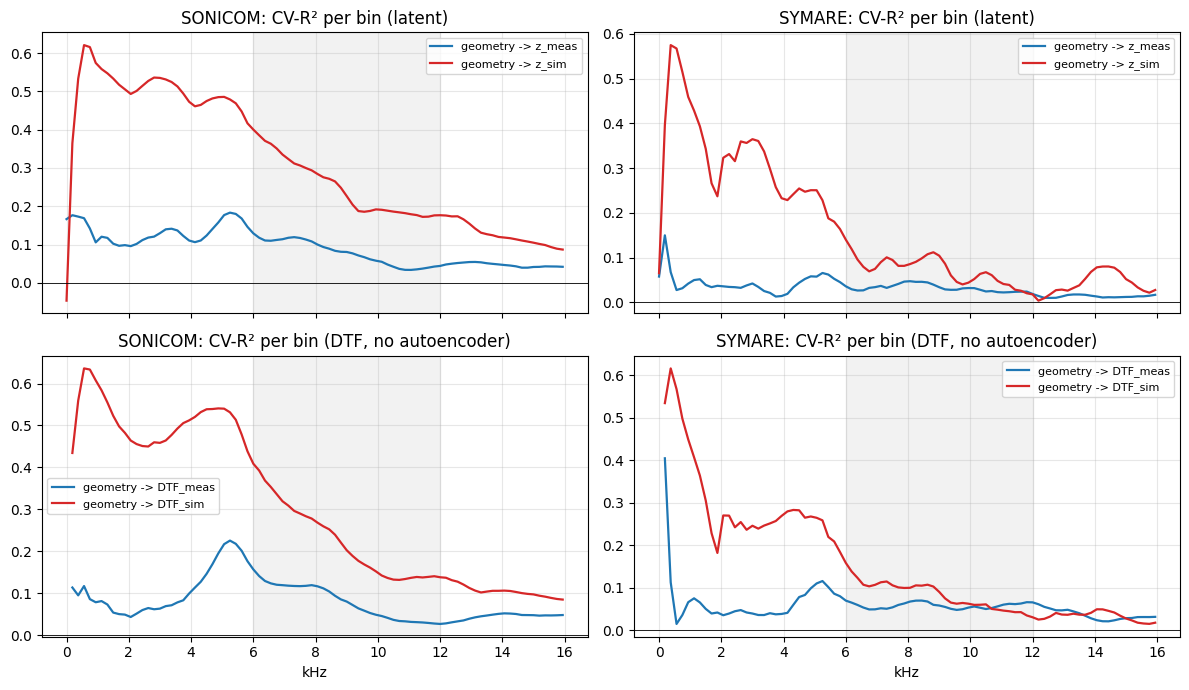


                                           SONICOM      SYMARE
geometry -> z_meas                         +0.0694     +0.0254
geometry -> z_sim                          +0.1966     +0.0744
geometry -> DTF_meas                       +0.0693     +0.0509
geometry -> DTF_sim                        +0.1727     +0.0652
simulation -> z_meas                       +0.0905     +0.0800
geometry + simulation -> z_meas            +0.0972     +0.0556
simulation -> DTF_meas                     +0.0912     +0.1417
geometry + simulation -> DTF_meas          +0.0987     +0.1188

结果 -> /content/drive/MyDrive/HRTF_Checkpoints/task1_v1/task1_results.json, task1_r2_per_bin.png


In [11]:
# ==========================================================================
# Cell 9 — 保存 · 图
# ==========================================================================
import matplotlib.pyplot as plt
RES = dict(created=time.strftime('%Y-%m-%d %H:%M:%S'), notebook='task1/Task1_SimVsMeas.ipynb',
           encoder='FFM48k_measim_best.pth', n_perm=N_PERM, n_boot=N_BOOT,
           databases={'SONICOM': RES_S, 'SYMARE': RES_Y})
json.dump(RES, open(f'{OUT}/task1_results.json', 'w'), indent=1, default=float)

fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for i, db in enumerate(('SONICOM', 'SYMARE')):
    pb = RES['databases'][db]['per_bin']
    for j, kind in enumerate(('z', 'DTF')):
        a = ax[j, i]
        f = FREQS / 1000 if kind == 'z' else FREQS[1:] / 1000
        for dom, c in (('meas', 'C0'), ('sim', 'C3')):
            a.plot(f, pb[f'geometry -> {kind}_{dom}'], c=c, lw=1.6, label=f'geometry -> {kind}_{dom}')
        a.axhline(0, c='k', lw=.6); a.axvspan(6, 12, color='grey', alpha=.1); a.grid(alpha=.3); a.legend(fontsize=8)
        a.set_title(f'{db}: CV-R² per bin ({"latent" if kind == "z" else "DTF, no autoencoder"})')
        if j == 1: a.set_xlabel('kHz')
plt.tight_layout(); plt.savefig(f'{OUT}/task1_r2_per_bin.png', dpi=140); plt.show()

print(f"\n{'':<38}{'SONICOM':>12}{'SYMARE':>12}")
for lbl in RES_S['cv']:
    print(f"{lbl:<38}{RES_S['cv'][lbl]['r2']:>+12.4f}{RES_Y['cv'][lbl]['r2']:>+12.4f}")
print(f'\n结果 -> {OUT}/task1_results.json, task1_r2_per_bin.png')